# Dimensión 3 — Mapeo en aplicación del ruteo de visitas de productos más importantes
Eber Brando Bravo Vega · Grupo 5

1. Carga e integración de tablas
2. Estadísticos descriptivos
3. Clasificación ABC y curva de Pareto
4. Puntualidad y retraso de las cargas Clase A
5. Mapa de concentración por estado de destino
6. Modelo predictivo (Ridge) de cargas Clase A semanales y comparación con pronósticos de referencia

In [ ]:
# Descarga del dataset desde Kaggle (Logistics Operations Database) a /content/modelamiento/
import os, shutil, glob, kagglehub
RUTA = "/content/modelamiento/"
os.makedirs(RUTA, exist_ok=True)
if not os.path.exists(RUTA + "loads.csv"):
    origen = kagglehub.dataset_download("yogape/logistics-operations-database")
    for f in glob.glob(os.path.join(origen, "**", "*.csv"), recursive=True):
        shutil.copy(f, RUTA)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

loads = pd.read_csv(RUTA + "loads.csv", parse_dates=["load_date"])
routes = pd.read_csv(RUTA + "routes.csv")
delivery_events = pd.read_csv(RUTA + "delivery_events.csv")
facilities = pd.read_csv(RUTA + "facilities.csv")

for nombre, df in [("loads", loads), ("routes", routes),
                   ("delivery_events", delivery_events), ("facilities", facilities)]:
    print(f"{nombre}: {df.shape} -> {df.columns.tolist()}")

loads: (85410, 12) -> ['load_id', 'customer_id', 'route_id', 'load_date', 'load_type', 'weight_lbs', 'pieces', 'revenue', 'fuel_surcharge', 'accessorial_charges', 'load_status', 'booking_type']
routes: (58, 9) -> ['route_id', 'origin_city', 'origin_state', 'destination_city', 'destination_state', 'typical_distance_miles', 'base_rate_per_mile', 'fuel_surcharge_rate', 'typical_transit_days']
delivery_events: (170820, 11) -> ['event_id', 'load_id', 'trip_id', 'event_type', 'facility_id', 'scheduled_datetime', 'actual_datetime', 'detention_minutes', 'on_time_flag', 'location_city', 'location_state']
facilities: (50, 9) -> ['facility_id', 'facility_name', 'facility_type', 'city', 'state', 'latitude', 'longitude', 'dock_doors', 'operating_hours']


## 1. Integración: una fila por carga con su evento de entrega y su instalación de destino

In [ ]:
entregas = delivery_events.loc[delivery_events["event_type"] == "Delivery"].copy()
entregas["scheduled_datetime"] = pd.to_datetime(entregas["scheduled_datetime"], errors="coerce")
entregas["actual_datetime"] = pd.to_datetime(entregas["actual_datetime"], errors="coerce")
entregas["desviacion_minutos"] = (
    entregas["actual_datetime"] - entregas["scheduled_datetime"]
).dt.total_seconds() / 60
entregas["puntual"] = entregas["actual_datetime"] <= entregas["scheduled_datetime"]

# Si delivery_events usa otro nombre para la instalación, ajustarlo aquí
assert "facility_id" in entregas.columns, entregas.columns.tolist()

datos = (
    loads
    .merge(routes[["route_id", "typical_distance_miles"]], on="route_id",
           how="left", validate="many_to_one")
    .merge(entregas[["load_id", "facility_id", "scheduled_datetime", "actual_datetime",
                     "desviacion_minutos", "puntual"]],
           on="load_id", how="left", validate="one_to_one")
    .merge(facilities[["facility_id", "state", "latitude", "longitude"]],
           on="facility_id", how="left", validate="many_to_one")
)
print("Registros integrados:", len(datos))
print("Cargas sin evento de entrega:", datos["actual_datetime"].isna().sum())
print("Cargas sin coordenadas de destino:", datos["latitude"].isna().sum())

Registros integrados: 85410
Cargas sin evento de entrega: 0
Cargas sin coordenadas de destino: 0


## 2. Estadísticos descriptivos de las variables de la dimensión

In [ ]:
variables = datos[["revenue", "weight_lbs", "pieces", "typical_distance_miles",
                   "desviacion_minutos"]].rename(columns={
    "revenue": "Ingreso (USD)",
    "weight_lbs": "Peso (lb)",
    "pieces": "Piezas",
    "typical_distance_miles": "Distancia típica de ruta (mi)",
    "desviacion_minutos": "Desviación del horario de entrega (min)",
})

def calcular_moda(serie):
    frecuencias = serie.dropna().value_counts()
    if frecuencias.empty or frecuencias.max() == 1:
        return "Sin moda"
    modas = frecuencias[frecuencias == frecuencias.max()].index
    return "; ".join(f"{v:,.2f}" for v in sorted(modas))

tabla = variables.agg(["mean", "std", "min", "max"]).T
tabla.columns = ["Promedio", "Desv. estándar", "Mínimo", "Máximo"]
tabla.insert(1, "Moda", variables.apply(calcular_moda))
tabla.index.name = "Variable"
display(tabla.style.format({c: "{:,.2f}" for c in ["Promedio", "Desv. estándar", "Mínimo", "Máximo"]})
        .set_caption("Estadísticos descriptivos — Dimensión 3"))

,Promedio,Moda,Desv. estándar,Mínimo,Máximo
Variable,,,,,
Ingreso (USD),"3,073.71","1,373.16","1,883.13",125.93,"8,125.22"
Peso (lb),"27,477.50","12,130.00; 20,740.00; 21,809.00; 26,742.00","10,095.42","10,000.00","45,000.00"
Piezas,14.47,13.00,8.07,1.00,28.00
Distancia típica de ruta (mi),"1,389.27",92.00,777.37,92.00,"3,141.00"
Desviación del horario de entrega (min),90.32,Sin moda,155.86,-179.99,360.00


## 3. Clasificación ABC por ingreso y curva de Pareto

,cargas,ingreso,% cargas,% ingreso
clase,,,,
A,47122,2.100188e+08,55.17,80.0
B,22224,3.938064e+07,26.02,15.0
C,16064,1.312634e+07,18.81,5.0


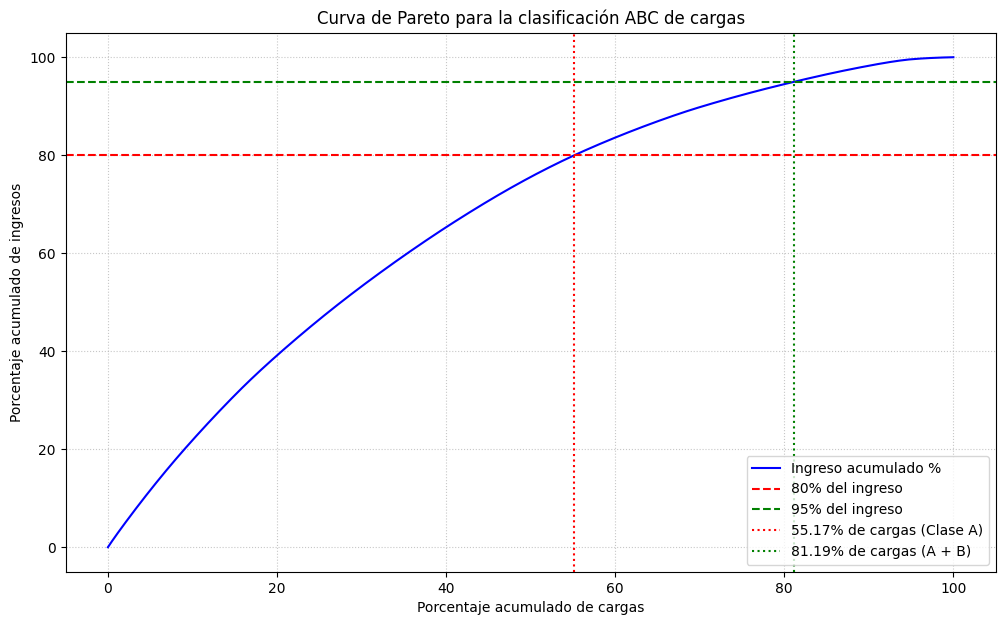

In [ ]:
datos = datos.sort_values("revenue", ascending=False).reset_index(drop=True)
datos["ingreso_acum_pct"] = datos["revenue"].cumsum() / datos["revenue"].sum() * 100
datos["cargas_acum_pct"] = (datos.index + 1) / len(datos) * 100

datos["clase"] = "C"
datos.loc[datos["ingreso_acum_pct"] <= 80, "clase"] = "A"
datos.loc[(datos["ingreso_acum_pct"] > 80) & (datos["ingreso_acum_pct"] <= 95), "clase"] = "B"

resumen_abc = datos.groupby("clase").agg(cargas=("load_id", "count"), ingreso=("revenue", "sum"))
resumen_abc["% cargas"] = resumen_abc["cargas"] / resumen_abc["cargas"].sum() * 100
resumen_abc["% ingreso"] = resumen_abc["ingreso"] / resumen_abc["ingreso"].sum() * 100
display(resumen_abc.round(2))

x80 = datos.loc[datos["ingreso_acum_pct"] >= 80, "cargas_acum_pct"].iloc[0]
x95 = datos.loc[datos["ingreso_acum_pct"] >= 95, "cargas_acum_pct"].iloc[0]

plt.figure(figsize=(12, 7))
plt.plot(datos["cargas_acum_pct"], datos["ingreso_acum_pct"], color="blue", label="Ingreso acumulado %")
plt.axhline(80, color="red", linestyle="--", label="80% del ingreso")
plt.axhline(95, color="green", linestyle="--", label="95% del ingreso")
plt.axvline(x80, color="red", linestyle=":", label=f"{x80:.2f}% de cargas (Clase A)")
plt.axvline(x95, color="green", linestyle=":", label=f"{x95:.2f}% de cargas (A + B)")
plt.title("Curva de Pareto para la clasificación ABC de cargas")
plt.xlabel("Porcentaje acumulado de cargas")
plt.ylabel("Porcentaje acumulado de ingresos")
plt.grid(True, linestyle=":", alpha=0.7)
plt.legend(loc="lower right")
plt.show()

## 4. Puntualidad y retraso de las cargas Clase A

In [ ]:
clase_a = datos[datos["clase"] == "A"].copy()
con_entrega = clase_a.dropna(subset=["actual_datetime", "scheduled_datetime"])

pct_puntual = con_entrega["puntual"].mean() * 100
retraso_medio = con_entrega["desviacion_minutos"].mean()
retraso_solo_tardias = con_entrega.loc[con_entrega["desviacion_minutos"] > 0, "desviacion_minutos"].mean()

print(f"Cargas Clase A: {len(clase_a):,} ({len(clase_a) / len(datos) * 100:.2f}% del total)")
print(f"Entregas puntuales (real <= programada): {pct_puntual:.2f}%")
print(f"Desviación media real - programada: {retraso_medio:.2f} min (incluye adelantos)")
print(f"Retraso medio de las entregas tardías: {retraso_solo_tardias:.2f} min")

Cargas Clase A: 47,122 (55.17% del total)
Entregas puntuales (real <= programada): 33.38%
Desviación media real - programada: 89.84 min (incluye adelantos)
Retraso medio de las entregas tardías: 179.69 min


## 5. Concentración geográfica de cargas Clase A por estado de destino

,state,cargas_A,puntualidad,desviacion_media_min,participacion_%
16,TN,4728,33.10,91.68,10.03
17,TX,4642,33.02,94.15,9.85
7,MI,3793,33.75,88.84,8.05
6,IN,3759,33.55,87.88,7.98
4,GA,3748,33.78,89.08,7.95
9,NC,2849,32.22,92.88,6.05
3,FL,2773,33.93,90.69,5.88
11,NV,2752,32.01,92.36,5.84
1,CA,1950,34.21,88.93,4.14
19,WI,1949,33.71,89.68,4.14


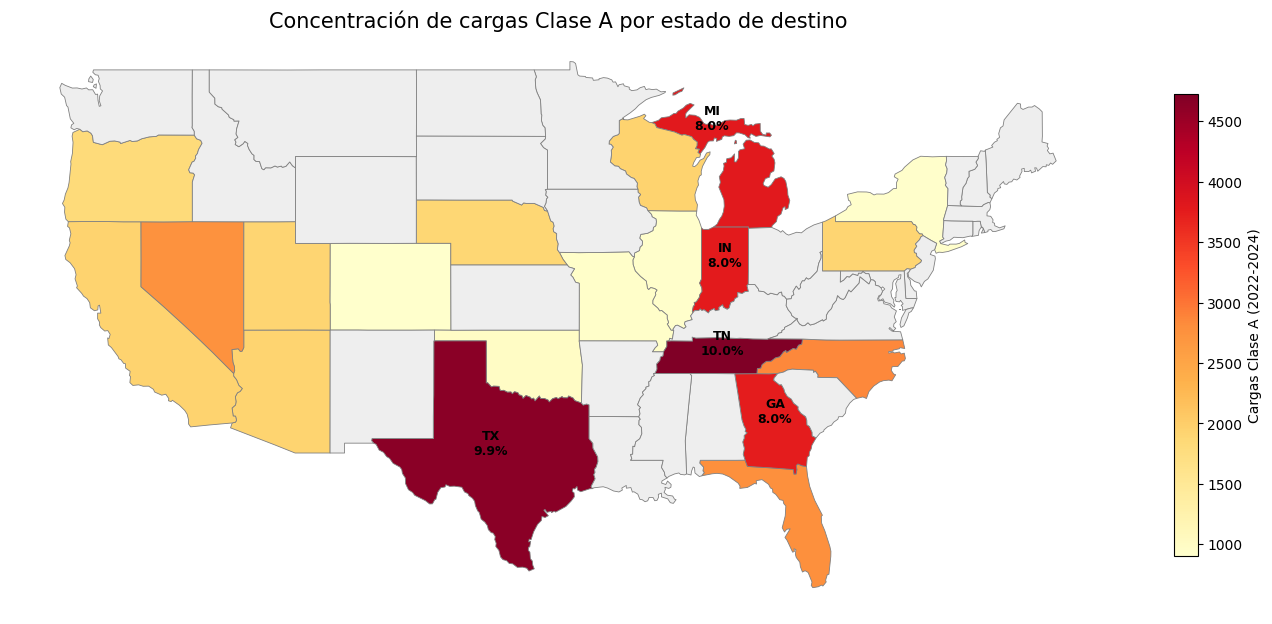

In [ ]:
import plotly.express as px

por_estado = (clase_a.dropna(subset=["state"])
              .groupby("state")
              .agg(cargas_A=("load_id", "nunique"),
                   puntualidad=("puntual", "mean"),
                   desviacion_media_min=("desviacion_minutos", "mean"))
              .reset_index())
por_estado["participacion_%"] = por_estado["cargas_A"] / por_estado["cargas_A"].sum() * 100
por_estado["puntualidad"] = por_estado["puntualidad"] * 100
display(por_estado.sort_values("cargas_A", ascending=False).head(10).round(2))

fig = px.choropleth(
    por_estado, locations="state", locationmode="USA-states", scope="usa",
    color="cargas_A", color_continuous_scale="YlOrRd",
    hover_data={"participacion_%": ":.2f", "puntualidad": ":.1f", "desviacion_media_min": ":.1f"},
    labels={"cargas_A": "Cargas Clase A", "puntualidad": "Puntualidad (%)"},
    title="Concentración de cargas Clase A por estado de destino",
)
fig.update_layout(title_x=0.5, margin=dict(l=20, r=20, t=60, b=20))
fig.show()

# Versión estática del mapa para el informe (matplotlib + geopandas)
import geopandas as gpd
estados = gpd.read_file("https://raw.githubusercontent.com/PublicaMundi/MappingAPI/master/data/geojson/us-states.json")
abrev = {"Alabama":"AL","Arizona":"AZ","Arkansas":"AR","California":"CA","Colorado":"CO","Connecticut":"CT","Delaware":"DE",
 "Florida":"FL","Georgia":"GA","Idaho":"ID","Illinois":"IL","Indiana":"IN","Iowa":"IA","Kansas":"KS","Kentucky":"KY",
 "Louisiana":"LA","Maine":"ME","Maryland":"MD","Massachusetts":"MA","Michigan":"MI","Minnesota":"MN","Mississippi":"MS",
 "Missouri":"MO","Montana":"MT","Nebraska":"NE","Nevada":"NV","New Hampshire":"NH","New Jersey":"NJ","New Mexico":"NM",
 "New York":"NY","North Carolina":"NC","North Dakota":"ND","Ohio":"OH","Oklahoma":"OK","Oregon":"OR","Pennsylvania":"PA",
 "Rhode Island":"RI","South Carolina":"SC","South Dakota":"SD","Tennessee":"TN","Texas":"TX","Utah":"UT","Vermont":"VT",
 "Virginia":"VA","Washington":"WA","West Virginia":"WV","Wisconsin":"WI","Wyoming":"WY"}
estados = estados[estados["name"].isin(abrev)].copy()
estados["state"] = estados["name"].map(abrev)
mapa = estados.merge(por_estado, on="state", how="left")

fig_m, ax = plt.subplots(figsize=(14, 8))
mapa.plot(column="cargas_A", cmap="YlOrRd", linewidth=0.6, edgecolor="gray", ax=ax, legend=True,
          legend_kwds={"label": "Cargas Clase A (2022-2024)", "shrink": 0.6},
          missing_kwds={"color": "#eeeeee", "label": "Sin cargas Clase A"})
for _, fila in mapa.dropna(subset=["cargas_A"]).sort_values("cargas_A", ascending=False).head(5).iterrows():
    p = fila.geometry.representative_point()
    ax.annotate(f"{fila['state']}\n{fila['participacion_%']:.1f}%", (p.x, p.y), ha="center", fontsize=9, weight="bold")
ax.set_title("Concentración de cargas Clase A por estado de destino", fontsize=15)
ax.set_axis_off()
plt.tight_layout()
plt.show()

In [ ]:
# Mapa de calor por coordenadas de las instalaciones de destino (complementario)
import folium
from folium.plugins import HeatMap

puntos = clase_a[["latitude", "longitude"]].dropna().values.tolist()
m = folium.Map(location=[39.8283, -98.5795], zoom_start=4)
HeatMap(puntos).add_to(m)
m.get_root().html.add_child(folium.Element(
    '<h3 align="center" style="font-size:20px"><b>Concentración geográfica de cargas Clase A</b></h3>'))
m

## 6. Modelo predictivo: cantidad semanal de cargas Clase A (Ridge)
- Serie semanal 2022-2024 (semanas completas, lunes a domingo).
- Sin rezago de 52 semanas: con tres años de datos eliminaría 2022 del entrenamiento. La estacionalidad anual se representa con seno y coseno.
- Variables estandarizadas, porque la penalización de Ridge depende de la escala.
- alpha elegido con validación temporal (TimeSeriesSplit) solo con 2022-2023; prueba en 2024.
- Comparación con tres pronósticos de referencia.

Serie semanal: 156 semanas (2022-01-09 a 2024-12-29)
Entrenamiento: 100 semanas | Prueba: 52 semanas


,alpha,MAE validación
0,0.010,19.313
1,0.032,19.146
2,0.100,19.008
3,0.316,18.806
4,1.000,18.407
5,3.162,17.386
6,10.000,15.653
7,31.623,13.960
8,100.000,13.397
9,316.228,13.481


Mejor alpha: 100


,Modelo,MAE,RMSE,MAPE (%)
0,Ridge,11.60,14.27,3.86
1,Ingenuo (semana anterior),16.00,20.29,5.35
2,Promedio móvil 4 semanas,13.68,16.47,4.57
3,Promedio de entrenamiento,12.11,14.68,4.06


,Coeficiente estandarizado
lag_1,-1.165
cos_anual,-1.076
sin_anual,0.959
trend,-0.888
rolling_mean_4,-0.661
lag_3,-0.295
lag_4,0.246
lag_2,0.057


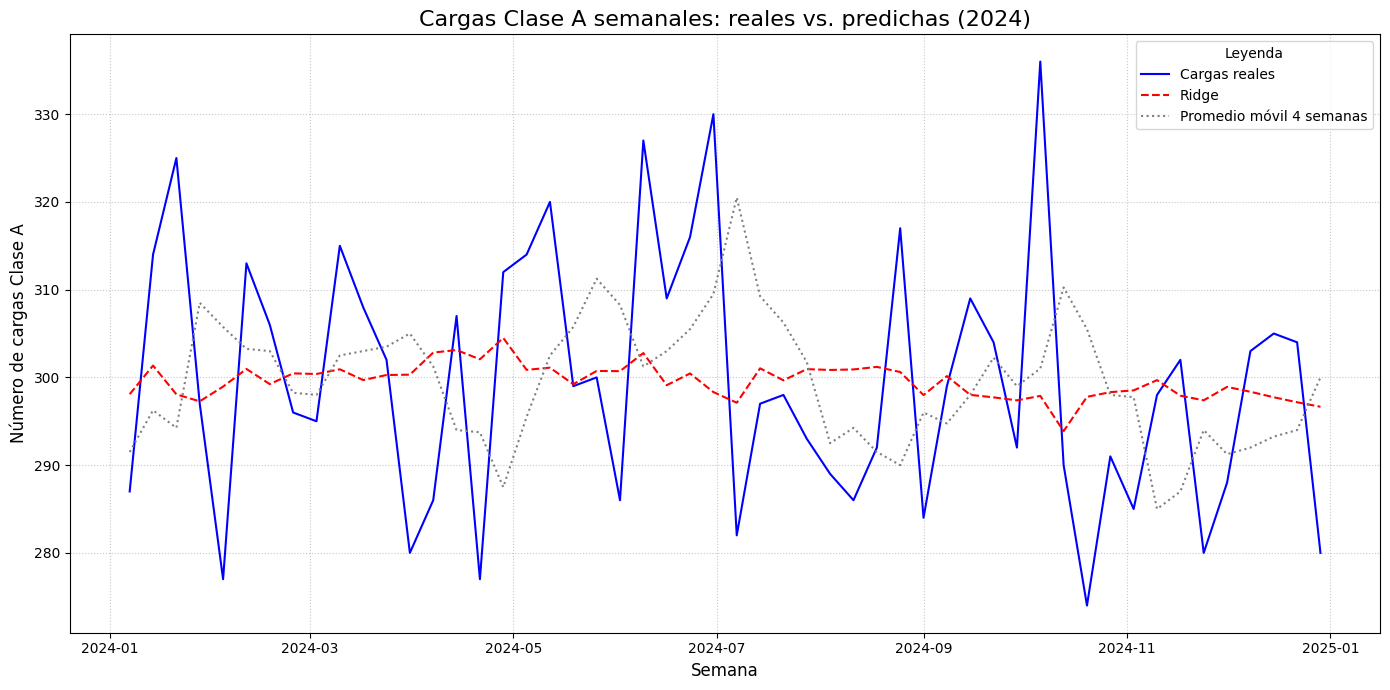

In [ ]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error

def metricas(y_real, y_pred):
    y_real, y_pred = np.asarray(y_real, float), np.asarray(y_pred, float)
    return (mean_absolute_error(y_real, y_pred),
            np.sqrt(mean_squared_error(y_real, y_pred)),
            np.mean(np.abs((y_real - y_pred) / y_real)) * 100)

serie = clase_a[(clase_a["load_date"] >= "2022-01-03") & (clase_a["load_date"] <= "2024-12-29")]
weekly = serie.set_index("load_date").resample("W-SUN")["load_id"].nunique().rename("num_loads_A")
print(f"Serie semanal: {len(weekly)} semanas ({weekly.index.min().date()} a {weekly.index.max().date()})")

X = pd.DataFrame(index=weekly.index)
for k in [1, 2, 3, 4]:
    X[f"lag_{k}"] = weekly.shift(k)
X["rolling_mean_4"] = weekly.rolling(4).mean().shift(1)
X["trend"] = np.arange(len(weekly))
semana = weekly.index.isocalendar().week.astype(int)
X["sin_anual"] = np.sin(2 * np.pi * semana / 52)
X["cos_anual"] = np.cos(2 * np.pi * semana / 52)

base = X.join(weekly).dropna()
features = list(X.columns)
train, test = base[base.index.year <= 2023], base[base.index.year == 2024]
X_train, y_train = train[features], train["num_loads_A"]
X_test, y_test = test[features], test["num_loads_A"]
print(f"Entrenamiento: {len(train)} semanas | Prueba: {len(test)} semanas")

alphas = np.logspace(-2, 4, 13)
tscv = TimeSeriesSplit(n_splits=5)
filas = []
for alpha in alphas:
    maes = []
    for tr, va in tscv.split(X_train):
        mod = Pipeline([("scaler", StandardScaler()), ("ridge", Ridge(alpha=alpha))])
        mod.fit(X_train.iloc[tr], y_train.iloc[tr])
        maes.append(mean_absolute_error(y_train.iloc[va], mod.predict(X_train.iloc[va])))
    filas.append({"alpha": alpha, "MAE validación": np.mean(maes)})
tabla_alpha = pd.DataFrame(filas)
display(tabla_alpha.round(3))
best_alpha = tabla_alpha.loc[tabla_alpha["MAE validación"].idxmin(), "alpha"]
print(f"Mejor alpha: {best_alpha:g}")

modelo = Pipeline([("scaler", StandardScaler()), ("ridge", Ridge(alpha=best_alpha))])
modelo.fit(X_train, y_train)
y_pred = np.clip(modelo.predict(X_test), 0, None)

ref_ingenuo = weekly.shift(1).loc[test.index]
ref_movil = weekly.rolling(4).mean().shift(1).loc[test.index]
ref_media = pd.Series(y_train.mean(), index=test.index)

comparacion = pd.DataFrame(
    [("Ridge", *metricas(y_test, y_pred)),
     ("Ingenuo (semana anterior)", *metricas(y_test, ref_ingenuo)),
     ("Promedio móvil 4 semanas", *metricas(y_test, ref_movil)),
     ("Promedio de entrenamiento", *metricas(y_test, ref_media))],
    columns=["Modelo", "MAE", "RMSE", "MAPE (%)"])
display(comparacion.round(2))

coef = pd.Series(modelo.named_steps["ridge"].coef_, index=features).sort_values(key=abs, ascending=False)
display(coef.round(3).to_frame("Coeficiente estandarizado"))

plt.figure(figsize=(14, 7))
plt.plot(y_test.index, y_test.values, color="blue", label="Cargas reales")
plt.plot(y_test.index, y_pred, color="red", linestyle="--", label="Ridge")
plt.plot(y_test.index, ref_movil.values, color="gray", linestyle=":", label="Promedio móvil 4 semanas")
plt.title("Cargas Clase A semanales: reales vs. predichas (2024)", fontsize=16)
plt.xlabel("Semana", fontsize=12)
plt.ylabel("Número de cargas Clase A", fontsize=12)
plt.legend(title="Leyenda")
plt.grid(True, linestyle=":", alpha=0.7)
plt.tight_layout()
plt.show()

## 7. Reducción de dimensiones mediante selección de variables predictoras
Mismo esquema que la dimensión 2: entrenamiento 2022, validación 2023 y prueba 2024.
1. Se entrena Ridge con las 8 variables en 2022 y se mide la importancia por permutación en 2023.
2. Se conservan las variables con importancia positiva (como máximo 4).
3. Se comparan el modelo completo y el reducido en 2024, ambos entrenados con 2022-2023.

In [ ]:
import time
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score

tr22 = base[base.index.year == 2022]
va23 = base[base.index.year == 2023]

mod_sel = Pipeline([("scaler", StandardScaler()), ("ridge", Ridge(alpha=best_alpha))])
mod_sel.fit(tr22[features], tr22["num_loads_A"])
perm = permutation_importance(mod_sel, va23[features], va23["num_loads_A"],
                              scoring="neg_mean_absolute_error", n_repeats=30, random_state=42)
importancia = (pd.DataFrame({"Variable": features,
                             "Aumento del MAE al permutar": perm.importances_mean,
                             "Desv. est.": perm.importances_std})
               .sort_values("Aumento del MAE al permutar", ascending=False))
display(importancia.round(3))

seleccion = importancia.loc[importancia["Aumento del MAE al permutar"] > 0, "Variable"].head(4).tolist()
if len(seleccion) < 2:
    seleccion = importancia["Variable"].head(2).tolist()
print("Variables seleccionadas:", seleccion)

def evaluar(cols, nombre):
    mod = Pipeline([("scaler", StandardScaler()), ("ridge", Ridge(alpha=best_alpha))])
    t0 = time.perf_counter()
    for _ in range(200):  # se repite para medir un tiempo estable
        mod.fit(X_train[cols], y_train)
    t = (time.perf_counter() - t0) / 200 * 1000
    pred = np.clip(mod.predict(X_test[cols]), 0, None)
    mae, rmse, mape = metricas(y_test, pred)
    return {"Modelo": nombre, "Variables": len(cols), "MAE": mae, "RMSE": rmse,
            "MAPE (%)": mape, "R²": r2_score(y_test, pred), "Entrenamiento (ms)": t}

tabla_reduccion = pd.DataFrame([evaluar(features, "Completo"), evaluar(seleccion, "Reducido")])
display(tabla_reduccion.round(4))

,Variable,Aumento del MAE al permutar,Desv. est.
7,cos_anual,0.071,0.059
6,sin_anual,0.033,0.027
0,lag_1,0.021,0.053
5,trend,-0.007,0.058
3,lag_4,-0.016,0.028
1,lag_2,-0.104,0.089
2,lag_3,-0.113,0.084
4,rolling_mean_4,-0.213,0.188


Variables seleccionadas: ['cos_anual', 'sin_anual', 'lag_1']


,Modelo,Variables,MAE,RMSE,MAPE (%),R²,Entrenamiento (ms)
0,Completo,8,11.6005,14.2724,3.8633,0.0359,4.5502
1,Reducido,3,12.0294,14.5097,4.0353,0.0036,3.9706
